# GreenFlow: Predicting Traffic Congestion to Reduce Fuel Waste and CO2 Emissions

CS316 Introduction to AI and Data Science, Term 261 (Phase 2)

- Faisal Almusallam (223110267)
- Abdulrahaman bin Saeed (223110148)

In this notebook we predict hourly traffic on a highway, classify how congested each hour is, and then estimate how much extra CO2 the congestion causes. Then we test what happens to emissions if some drivers travel outside the rush hour. In section 10 we do the same kind of analysis on data we collected ourselves from main roads in Riyadh.

Data:

- [Metro Interstate Traffic Volume](https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume) from the UCI Machine Learning Repository (Hogue, 2019)
- our own Riyadh data, collected every 15 minutes from the TomTom Traffic Flow API (`riyadh_collector.py`)

## 0. Imports and settings

In [1]:
import gc
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, silhouette_score)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance

# fixed seed so we get the same results every time we run it
RANDOM_STATE = 42

DATA_PATH = Path('data') / 'Metro_Interstate_Traffic_Volume.csv.gz'
FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:,.3f}'.format)


def save(fig, name):
    # we save every figure so we can use it in the report
    fig.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

## 1. Loading the data

First we load the file normally just to see how much memory it takes. Then we load it again with smaller data types (float32, int16, int8 and category) and read it in chunks. The dataset is small, but this would matter a lot for a bigger dataset covering a whole city.

In [2]:
# normal load, only to measure the memory
raw = pd.read_csv(DATA_PATH)
mem_before = raw.memory_usage(deep=True).sum() / 1024**2
print('Shape:', raw.shape)
del raw
gc.collect()

# smaller types (traffic max is 7280 so int16 is enough, clouds is 0-100 so int8)
DTYPES = {'holiday': 'category', 'temp': 'float32', 'rain_1h': 'float32', 'snow_1h': 'float32',
          'clouds_all': 'int8', 'weather_main': 'category', 'weather_description': 'category',
          'traffic_volume': 'int16'}

# read the file 10,000 rows at a time
chunks = []
for chunk in pd.read_csv(DATA_PATH, dtype=DTYPES, parse_dates=['date_time'], chunksize=10_000):
    chunks.append(chunk)
df = pd.concat(chunks, ignore_index=True)
del chunks
gc.collect()

# concat can turn the category columns back to text, so we convert them again
CAT_COLS = ['holiday', 'weather_main', 'weather_description']
df[CAT_COLS] = df[CAT_COLS].astype('category')

mem_after = df.memory_usage(deep=True).sum() / 1024**2
print(f'Memory before: {mem_before:.2f} MB, after: {mem_after:.2f} MB '
      f'({100 * (1 - mem_after / mem_before):.1f}% less)')
df.head()

Shape: (48204, 9)
Memory before: 11.71 MB, after: 1.20 MB (89.8% less)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.280,0.000,0.000,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.360,0.000,0.000,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.580,0.000,0.000,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.130,0.000,0.000,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.140,0.000,0.000,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [3]:
df.info(memory_usage='deep')
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              61 non-null     category      
 1   temp                 48204 non-null  float32       
 2   rain_1h              48204 non-null  float32       
 3   snow_1h              48204 non-null  float32       
 4   clouds_all           48204 non-null  int8          
 5   weather_main         48204 non-null  category      
 6   weather_description  48204 non-null  category      
 7   date_time            48204 non-null  datetime64[us]
 8   traffic_volume       48204 non-null  int16         
dtypes: category(3), datetime64[us](1), float32(3), int16(1), int8(1)
memory usage: 1.2 MB


,count,mean,min,25%,50%,75%,max,std
temp,"48,204.000",281.206,0.000,272.160,282.450,291.806,310.070,13.338
rain_1h,"48,204.000",0.334,0.000,0.000,0.000,0.000,"9,831.300",44.789
snow_1h,"48,204.000",0.000,0.000,0.000,0.000,0.000,0.510,0.008
clouds_all,"48,204.000",49.362,0.000,1.000,64.000,90.000,100.000,39.016
date_time,48204,2016-01-05 10:46:16.773711,2012-10-02 09:00:00,2014-02-06 11:45:00,2016-06-11 03:30:00,2017-08-11 06:00:00,2018-09-30 23:00:00,NaN
traffic_volume,"48,204.000","3,259.818",0.000,"1,193.000","3,380.000","4,933.000","7,280.000","1,986.861"


## 2. Cleaning

While looking at the data we found some problems:

- The holiday name only appears on the midnight row, so the rest of the holiday looks like a normal day.
- A few rows have a temperature of 0 Kelvin, which is impossible.
- One row has 9,831 mm of rain in one hour, which is clearly a sensor error.
- Some hours appear more than once (one row for each weather condition).
- Some hours are missing completely because the sensor was not working.

In [4]:
n_raw = len(df)

# copy the holiday name to all hours of that day
df['date'] = df['date_time'].dt.normalize()
holiday_days = df.loc[df['holiday'].notna(), ['date', 'holiday']].drop_duplicates('date')
df = df.drop(columns='holiday').merge(holiday_days, on='date', how='left')
df['is_holiday'] = df['holiday'].notna().astype('int8')
print('Holiday hours after the fix:', int(df['is_holiday'].sum()))

# wrong values
n_bad_temp = int((df['temp'] == 0).sum())
df.loc[df['temp'] == 0, 'temp'] = np.nan
n_bad_rain = int((df['rain_1h'] > 100).sum())
df.loc[df['rain_1h'] > 100, 'rain_1h'] = 0.0
print(f'Fixed {n_bad_temp} rows with 0 K temperature and {n_bad_rain} row(s) with wrong rain')

# repeated hours (traffic is the same in all copies, so we keep the first one)
n_dupes = int(df['date_time'].duplicated().sum())
df = df.sort_values('date_time').drop_duplicates('date_time', keep='first').set_index('date_time')
print(f'Removed {n_dupes} repeated hours')

# put the data on a full hourly grid, so missing hours become NaN rows.
# we need this for the lag features, otherwise "1 hour ago" could be days ago
full_index = pd.date_range(df.index.min(), df.index.max(), freq='h')
n_missing = len(full_index) - len(df)
df = df.reindex(full_index)
df.index.name = 'date_time'
df['temp'] = df['temp'].interpolate(limit=6)
print(f'Missing hours: {n_missing:,} ({100 * n_missing / len(full_index):.1f}%)')
print(f'Rows: {n_raw:,} in the raw file, {df["traffic_volume"].notna().sum():,} unique hours with traffic')

Holiday hours after the fix: 1409
Fixed 10 rows with 0 K temperature and 1 row(s) with wrong rain
Removed 7629 repeated hours
Missing hours: 11,976 (22.8%)
Rows: 48,204 in the raw file, 40,575 unique hours with traffic


## 3. Feature engineering

We add:

- time features: hour, day of week, month, weekend, holiday
- sin and cos of the hour, day and month (so the model knows that hour 23 is close to hour 0)
- lag features: traffic 1 hour ago, 24 hours ago and 168 hours ago (same hour last week), and the average of the last 24 hours
- weather: temperature in Celsius, rain, snow, clouds, and one column for each weather type

We also make two sets of features. The full set uses the lags and is meant for predicting the next hour. The "planning" set has no lags, so it could be used to predict days ahead.

In [5]:
idx = df.index
df['hour'] = idx.hour.astype('int8')
df['dayofweek'] = idx.dayofweek.astype('int8')     # 0 = Monday
df['month'] = idx.month.astype('int8')
df['year'] = idx.year.astype('int16')
df['is_weekend'] = (df['dayofweek'] >= 5).astype('int8')
df['is_holiday'] = df['is_holiday'].fillna(0).astype('int8')

for col, period in [('hour', 24), ('dayofweek', 7), ('month', 12)]:
    df[f'{col}_sin'] = np.sin(2 * np.pi * df[col] / period).astype('float32')
    df[f'{col}_cos'] = np.cos(2 * np.pi * df[col] / period).astype('float32')

# lag features
y_all = df['traffic_volume'].astype('float32')
df['lag_1'] = y_all.shift(1)
df['lag_24'] = y_all.shift(24)
df['lag_168'] = y_all.shift(168)
df['roll_mean_24'] = y_all.shift(1).rolling(24, min_periods=18).mean()

# weather
df['temp_c'] = (df['temp'] - 273.15).astype('float32')
weather_dummies = pd.get_dummies(df['weather_main'], prefix='w', dtype='int8')
df = pd.concat([df, weather_dummies], axis=1)
WEATHER_COLS = list(weather_dummies.columns)

PLAN_FEATURES = (['hour', 'dayofweek', 'month', 'is_weekend', 'is_holiday',
                  'hour_sin', 'hour_cos', 'dayofweek_sin', 'dayofweek_cos', 'month_sin', 'month_cos',
                  'temp_c', 'rain_1h', 'snow_1h', 'clouds_all'] + WEATHER_COLS)
LAG_FEATURES = ['lag_1', 'lag_24', 'lag_168', 'roll_mean_24']
FULL_FEATURES = PLAN_FEATURES + LAG_FEATURES
TARGET = 'traffic_volume'

# drop rows where the target or any feature is missing
model_df = df.dropna(subset=FULL_FEATURES + [TARGET]).copy()
model_df[TARGET] = model_df[TARGET].astype('int16')
print(f'Rows for modelling: {len(model_df):,}, number of features: {len(FULL_FEATURES)}')

Rows for modelling: 34,029, number of features: 30


## 4. Exploratory data analysis

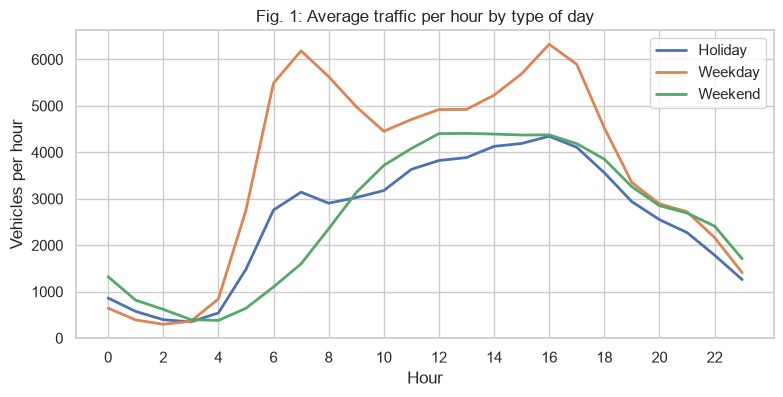

Busiest weekday hour: 16:00 with 6,325 vehicles per hour on average


In [6]:
obs = df.dropna(subset=[TARGET])

# average traffic per hour for weekdays, weekends and holidays
day_type = np.select([obs['is_holiday'] == 1, obs['is_weekend'] == 1], ['Holiday', 'Weekend'], 'Weekday')
profile = obs.groupby([day_type, 'hour'])[TARGET].mean().unstack(0)

fig, ax = plt.subplots(figsize=(9, 4))
profile.plot(ax=ax, lw=2)
ax.set(title='Fig. 1: Average traffic per hour by type of day', xlabel='Hour', ylabel='Vehicles per hour')
ax.set_xticks(range(0, 24, 2))
save(fig, 'fig1_hourly_profile')
plt.show()

peak_hour = int(profile['Weekday'].idxmax())
print(f'Busiest weekday hour: {peak_hour}:00 with {profile["Weekday"].max():,.0f} vehicles per hour on average')

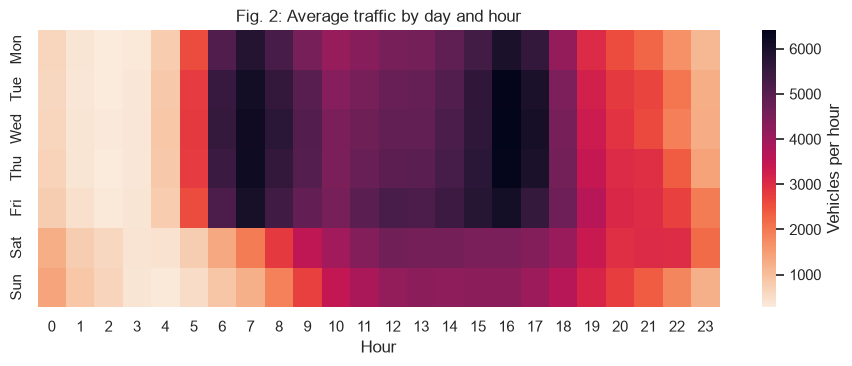

In [7]:
pivot = obs.pivot_table(index='dayofweek', columns='hour', values=TARGET, aggfunc='mean')
pivot.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(pivot, cmap='rocket_r', ax=ax, cbar_kws={'label': 'Vehicles per hour'})
ax.set(title='Fig. 2: Average traffic by day and hour', xlabel='Hour', ylabel='')
save(fig, 'fig2_heatmap_week')
plt.show()

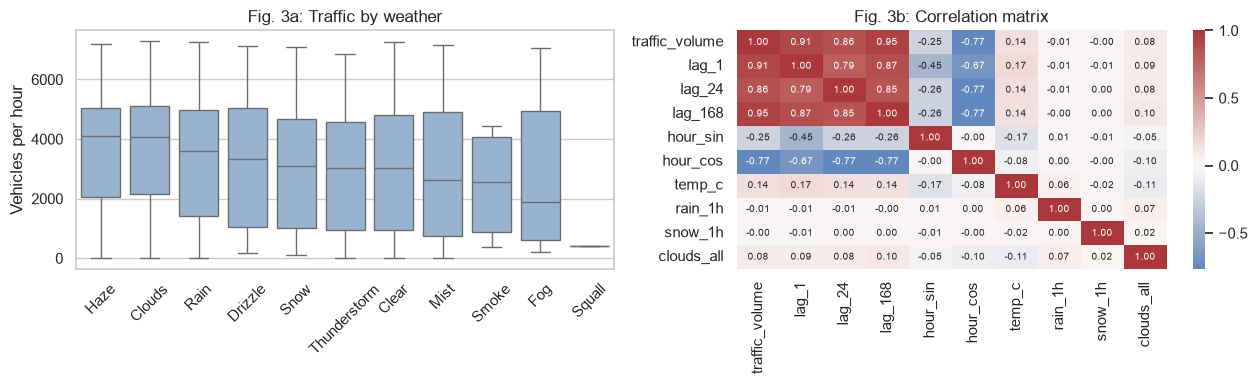

Months with data: 63 out of 72


In [8]:
order = obs.groupby('weather_main', observed=True)[TARGET].median().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=obs, x='weather_main', y=TARGET, order=order, ax=axes[0], color='#8fb3d9', fliersize=1)
axes[0].set(title='Fig. 3a: Traffic by weather', xlabel='', ylabel='Vehicles per hour')
axes[0].tick_params(axis='x', rotation=45)

corr_cols = [TARGET, 'lag_1', 'lag_24', 'lag_168', 'hour_sin', 'hour_cos', 'temp_c', 'rain_1h', 'snow_1h', 'clouds_all']
sns.heatmap(obs[corr_cols].corr(), annot=True, fmt='.2f', cmap='vlag', center=0, ax=axes[1], annot_kws={'size': 7})
axes[1].set_title('Fig. 3b: Correlation matrix')
fig.tight_layout()
save(fig, 'fig3_weather_corr')
plt.show()

monthly = obs[TARGET].resample('MS').mean()
print('Months with data:', monthly.notna().sum(), 'out of', len(monthly))

## 5. Regression: predicting the traffic volume

We train on 2012 to 2017 and test on 2018. We did not use a random split because the model would then be trained on hours that come after the test hours.

Models: linear regression (baseline), random forest and histogram gradient boosting (HGB). We also train the planning model without lag features.

In [9]:
train = model_df[model_df['year'] <= 2017]
test = model_df[model_df['year'] == 2018]
print(f'Train: {len(train):,} rows ({train.index.min():%Y-%m} to {train.index.max():%Y-%m})')
print(f'Test: {len(test):,} rows ({test.index.min():%Y-%m} to {test.index.max():%Y-%m})')

# float32 instead of float64 to save memory
X_train, X_test = train[FULL_FEATURES].astype('float32'), test[FULL_FEATURES].astype('float32')
y_train, y_test = train[TARGET].astype('float32'), test[TARGET].astype('float32')


def reg_scores(name, y_true, y_pred, seconds):
    return {'Model': name,
            'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred),
            'Train time (s)': seconds}


reg_models = {
    'Linear Regression (baseline)': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    'Hist Gradient Boosting': HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08, random_state=RANDOM_STATE),
}
reg_rows, reg_preds = [], {}
for name, model in reg_models.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    reg_preds[name] = pred
    reg_rows.append(reg_scores(name, y_test, pred, time.perf_counter() - t0))

# planning model (no lags)
t0 = time.perf_counter()
plan_model = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08, random_state=RANDOM_STATE)
plan_model.fit(train[PLAN_FEATURES].astype('float32'), y_train)
plan_pred = plan_model.predict(test[PLAN_FEATURES].astype('float32'))
reg_rows.append(reg_scores('HGB planning model (no lags)', y_test, plan_pred, time.perf_counter() - t0))

pd.DataFrame(reg_rows).set_index('Model')

Train: 27,544 rows (2012-10 to 2017-12)
Test: 6,485 rows (2018-01 to 2018-09)


,MAE,RMSE,R2,Train time (s)
Model,,,,
Linear Regression (baseline),310.164,457.290,0.946,0.032
Random Forest,148.774,237.494,0.985,2.305
Hist Gradient Boosting,144.966,223.239,0.987,0.586
HGB planning model (no lags),226.315,374.037,0.964,0.679


### 5.1 Tuning with time series cross validation

TimeSeriesSplit always validates on data that comes after the training part, which is closer to how the model would be used in real life.

In [10]:
tscv = TimeSeriesSplit(n_splits=4)
param_grid = {'learning_rate': [0.05, 0.1],
              'max_leaf_nodes': [31, 63],
              'l2_regularization': [0.0, 1.0]}

t0 = time.perf_counter()
search = GridSearchCV(HistGradientBoostingRegressor(max_iter=400, random_state=RANDOM_STATE),
                      param_grid, cv=tscv, scoring='neg_mean_absolute_error', n_jobs=-1)
search.fit(X_train, y_train)
best_reg = search.best_estimator_
best_pred = best_reg.predict(X_test)
reg_rows.append(reg_scores('HGB tuned (GridSearchCV)', y_test, best_pred, time.perf_counter() - t0))

print('Best parameters:', search.best_params_)
print(f'Cross validation MAE: {-search.best_score_:,.1f} vehicles per hour')
reg_table = pd.DataFrame(reg_rows).set_index('Model').sort_values('MAE')
reg_table

Best parameters: {'l2_regularization': 0.0, 'learning_rate': 0.05, 'max_leaf_nodes': 31}
Cross validation MAE: 167.0 vehicles per hour


,MAE,RMSE,R2,Train time (s)
Model,,,,
Hist Gradient Boosting,144.966,223.239,0.987,0.586
HGB tuned (GridSearchCV),145.433,223.847,0.987,7.245
Random Forest,148.774,237.494,0.985,2.305
HGB planning model (no lags),226.315,374.037,0.964,0.679
Linear Regression (baseline),310.164,457.290,0.946,0.032


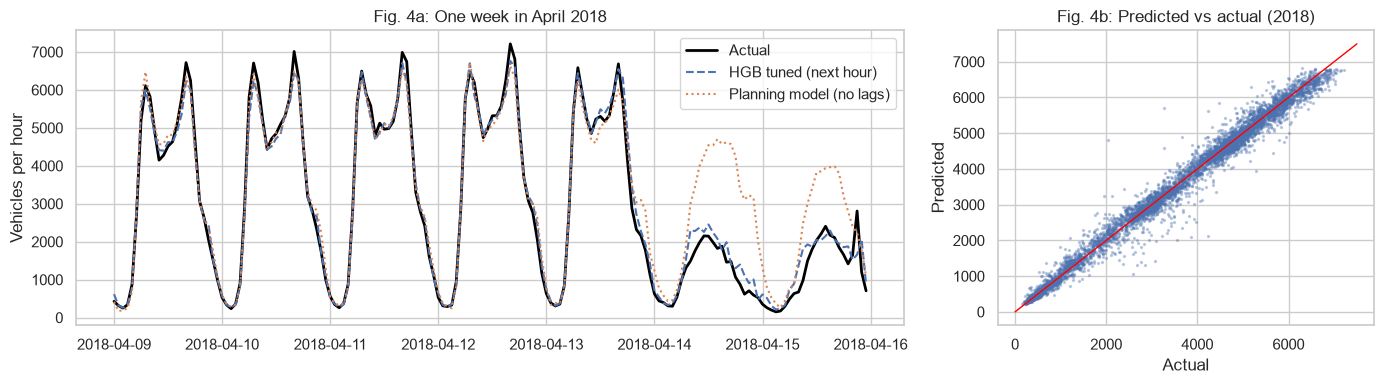

In [11]:
# one normal week in April 2018
mask = (test.index >= '2018-04-09') & (test.index < '2018-04-16')

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [2.2, 1]})
axes[0].plot(test.index[mask], y_test[mask], label='Actual', color='black', lw=2)
axes[0].plot(test.index[mask], best_pred[mask], label='HGB tuned (next hour)', ls='--')
axes[0].plot(test.index[mask], plan_pred[mask], label='Planning model (no lags)', ls=':')
axes[0].set(title='Fig. 4a: One week in April 2018', ylabel='Vehicles per hour')
axes[0].legend()

axes[1].scatter(y_test, best_pred, s=2, alpha=0.3)
axes[1].plot([0, 7500], [0, 7500], color='red', lw=1)
axes[1].set(title='Fig. 4b: Predicted vs actual (2018)', xlabel='Actual', ylabel='Predicted')
fig.tight_layout()
save(fig, 'fig4_regression')
plt.show()

## 6. Classification: predicting the congestion level

The dataset has no speed column, so we made 4 levels from the quartiles of the traffic volume in the training data (we only used the training data here so the test set does not affect the labels):

| Level | Traffic volume |
|---|---|
| 0 Low | below the 25th percentile |
| 1 Moderate | 25th to 50th percentile |
| 2 High | 50th to 75th percentile |
| 3 Severe | above the 75th percentile |

In [12]:
LEVELS = ['Low', 'Moderate', 'High', 'Severe']
cuts = train[TARGET].quantile([0.25, 0.50, 0.75]).values
print('Thresholds:', cuts.round(0))


def to_level(volume):
    return np.digitize(volume, cuts).astype('int8')


yc_train, yc_test = to_level(y_train), to_level(y_test)
print('Number of test hours per level:', np.bincount(yc_test))

clf_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'Decision Tree': DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, random_state=RANDOM_STATE),
    'KNN (k=15)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(max_iter=400, learning_rate=0.08, random_state=RANDOM_STATE),
}
clf_rows, clf_preds = [], {}
for name, model in clf_models.items():
    t0 = time.perf_counter()
    model.fit(X_train, yc_train)
    pred = model.predict(X_test)
    clf_preds[name] = pred
    clf_rows.append({'Model': name,
                     'Accuracy': accuracy_score(yc_test, pred),
                     'Macro F1': f1_score(yc_test, pred, average='macro'),
                     'Train time (s)': time.perf_counter() - t0})

# we also tried taking the regression prediction and converting it to a level
clf_preds['Tuned regressor -> level'] = to_level(best_pred)
clf_rows.append({'Model': 'Tuned regressor -> level', 'Accuracy': accuracy_score(yc_test, to_level(best_pred)),
                 'Macro F1': f1_score(yc_test, to_level(best_pred), average='macro'), 'Train time (s)': 0.0})

clf_table = pd.DataFrame(clf_rows).set_index('Model').sort_values('Accuracy', ascending=False)
clf_table

Thresholds: [1223. 3361. 4918.]
Number of test hours per level: [1548 1549 1697 1691]


,Accuracy,Macro F1,Train time (s)
Model,,,
Hist Gradient Boosting,0.928,0.929,0.704
Tuned regressor -> level,0.925,0.926,0.000
Random Forest,0.922,0.923,0.857
Decision Tree,0.903,0.905,0.163
Logistic Regression,0.889,0.891,0.190
KNN (k=15),0.857,0.858,0.207


Best classifier: Hist Gradient Boosting
              precision    recall  f1-score   support

         Low      0.976     0.973     0.974      1548
    Moderate      0.911     0.937     0.924      1549
        High      0.897     0.872     0.884      1697
      Severe      0.929     0.934     0.932      1691

    accuracy                          0.928      6485
   macro avg      0.928     0.929     0.929      6485
weighted avg      0.928     0.928     0.928      6485



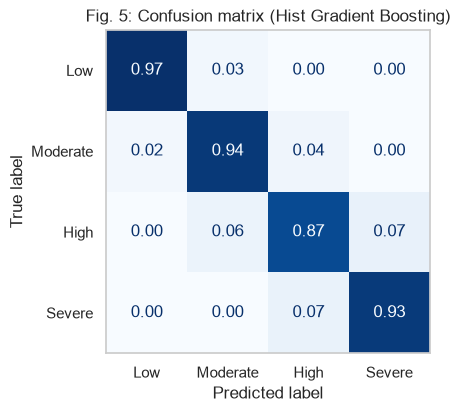

In [13]:
best_clf_name = clf_table.index[0]
best_clf_pred = clf_preds[best_clf_name]
print('Best classifier:', best_clf_name)
print(classification_report(yc_test, best_clf_pred, target_names=LEVELS, digits=3))

fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay(confusion_matrix(yc_test, best_clf_pred, normalize='true'),
                       display_labels=LEVELS).plot(ax=ax, cmap='Blues', values_format='.2f', colorbar=False)
ax.set_title(f'Fig. 5: Confusion matrix ({best_clf_name})')
ax.grid(False)
save(fig, 'fig5_confusion')
plt.show()

## 7. Clustering: types of days

Every day is turned into a vector of 24 values (traffic in each hour), and K-means groups similar days together. We chose k using the elbow method and the silhouette score, and used PCA to plot the days in 2D.

In [14]:
daily = obs.pivot_table(index='date', columns='hour', values=TARGET).dropna()
print('Complete days:', len(daily))
Xd = StandardScaler().fit_transform(daily.values).astype('float32')

ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xd)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xd, km.labels_))

# k=2 only separates weekdays from weekends, so we look for the best k from 3 up
best_k = max(range(3, 9), key=lambda k: sil[k - 2])
print('Silhouette scores:', dict(zip(ks, np.round(sil, 3))), '-> k =', best_k)

kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(Xd)
daily['cluster'] = kmeans.labels_

Complete days: 1214


Silhouette scores: {2: np.float64(0.492), 3: np.float64(0.463), 4: np.float64(0.275), 5: np.float64(0.248), 6: np.float64(0.21), 7: np.float64(0.208), 8: np.float64(0.193)} -> k = 3


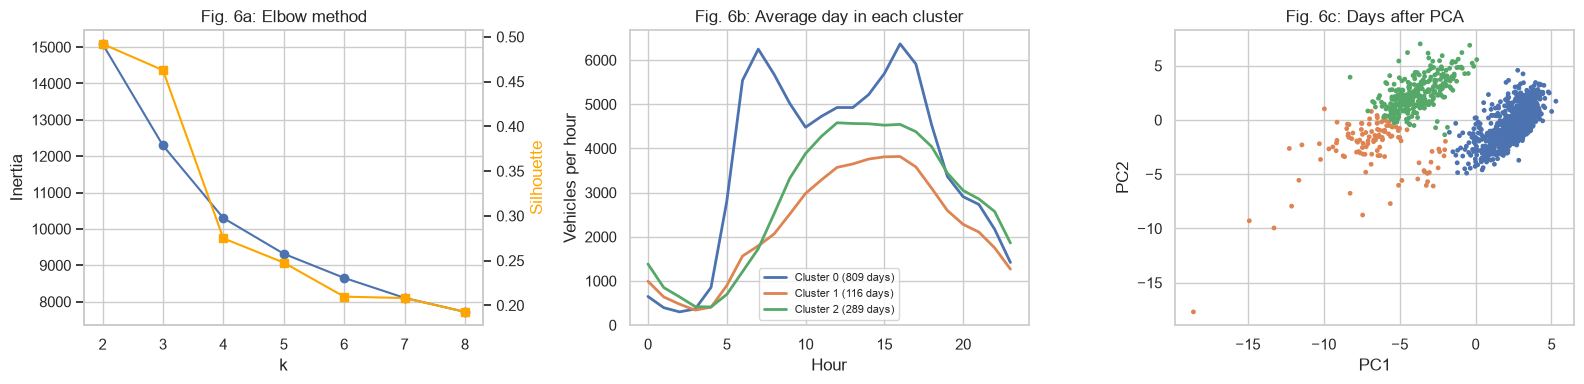

,days,weekend_share,holiday_share,mean_temp_c,mean_daily_vehicles
cluster,,,,,
0,809,0.000,0.012,9.698,"87,243.094"
1,116,0.612,0.216,1.871,"53,256.897"
2,289,0.983,0.003,11.493,"66,330.713"


In [15]:
# what kind of days are in each cluster
day_info = obs.groupby('date')[['is_weekend', 'is_holiday', 'temp_c', 'snow_1h', 'rain_1h']].mean()
summary = daily[['cluster']].join(day_info)
summary['total_traffic'] = daily.drop(columns='cluster').sum(axis=1)
cluster_table = summary.groupby('cluster').agg(days=('is_weekend', 'size'),
                                               weekend_share=('is_weekend', 'mean'),
                                               holiday_share=('is_holiday', 'mean'),
                                               mean_temp_c=('temp_c', 'mean'),
                                               mean_daily_vehicles=('total_traffic', 'mean'))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(list(ks), inertia, marker='o')
axes[0].set(title='Fig. 6a: Elbow method', xlabel='k', ylabel='Inertia')
ax2 = axes[0].twinx()
ax2.plot(list(ks), sil, marker='s', color='orange')
ax2.set_ylabel('Silhouette', color='orange')
ax2.grid(False)

hourly_cols = [c for c in daily.columns if c != 'cluster']
for c, grp in daily.groupby('cluster'):
    axes[1].plot(hourly_cols, grp[hourly_cols].mean(), lw=2, label=f'Cluster {c} ({len(grp)} days)')
axes[1].set(title='Fig. 6b: Average day in each cluster', xlabel='Hour', ylabel='Vehicles per hour')
axes[1].legend(fontsize=8)

pcs = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xd)
axes[2].scatter(pcs[:, 0], pcs[:, 1], c=[f'C{c}' for c in daily['cluster']], s=6)
axes[2].set(title='Fig. 6c: Days after PCA', xlabel='PC1', ylabel='PC2')
fig.tight_layout()
save(fig, 'fig6_clusters')
plt.show()
cluster_table

## 8. From traffic to CO2

We don't have speeds, so we estimate the delay with the BPR function, which is commonly used in transport planning:

$$t = t_0\left(1 + 0.15\left(\frac{v}{c}\right)^4\right)$$

where $t_0$ is the travel time on an empty road, $v$ is the traffic volume and $c$ is the road capacity. Then:

- delay (vehicle hours) = $v \times (t - t_0)$
- extra fuel = delay × fuel used per hour of delay
- CO2 = fuel × 8.887 kg per gallon (US EPA)

The results are per 1 mile of highway. Some of the constants below are our own assumptions, so the numbers are estimates. Because of the power of 4, most of the waste comes from the busiest hours.

Extra CO2 in the test period (actual traffic): 36.08 t
Extra CO2 in the test period (predicted traffic): 35.40 t
Difference: -1.9%
Per year, per mile: 48.74 t CO2
The busiest 25% of hours make 77% of the extra CO2


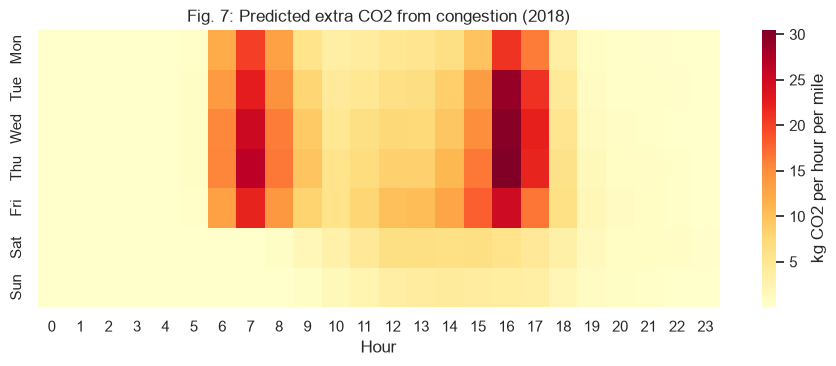

In [16]:
SEGMENT_MILES = 1.0
FREE_FLOW_MPH = 65.0
CAPACITY_VPH = 7_500.0         # assumption, a bit above the highest value in the data (7,280)
FUEL_GAL_PER_DELAY_H = 0.4     # assumption
CO2_KG_PER_GAL = 8.887         # US EPA


def excess_co2_kg(volume):
    v = np.asarray(volume, dtype='float64')
    t0 = SEGMENT_MILES / FREE_FLOW_MPH
    t = t0 * (1 + 0.15 * (v / CAPACITY_VPH) ** 4)
    delay_veh_h = v * (t - t0)
    return delay_veh_h * FUEL_GAL_PER_DELAY_H * CO2_KG_PER_GAL


test_em = test[['hour', 'dayofweek']].copy()
test_em['co2_actual'] = excess_co2_kg(y_test)
test_em['co2_pred'] = excess_co2_kg(np.clip(best_pred, 0, None))
hours_covered = len(test_em)
scale_to_year = 8_760 / hours_covered

print(f'Extra CO2 in the test period (actual traffic): {test_em.co2_actual.sum() / 1000:,.2f} t')
print(f'Extra CO2 in the test period (predicted traffic): {test_em.co2_pred.sum() / 1000:,.2f} t')
print(f'Difference: {100 * (test_em.co2_pred.sum() / test_em.co2_actual.sum() - 1):+.1f}%')
print(f'Per year, per mile: {test_em.co2_actual.sum() * scale_to_year / 1000:,.2f} t CO2')

# how much of the CO2 comes from the busiest quarter of the hours
share_top = (test_em.co2_actual.sort_values(ascending=False)
             .head(int(0.25 * hours_covered)).sum() / test_em.co2_actual.sum())
print(f'The busiest 25% of hours make {100 * share_top:.0f}% of the extra CO2')

co2_map = test_em.pivot_table(index='dayofweek', columns='hour', values='co2_pred', aggfunc='mean')
co2_map.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(co2_map, cmap='YlOrRd', ax=ax, cbar_kws={'label': 'kg CO2 per hour per mile'})
ax.set(title='Fig. 7: Predicted extra CO2 from congestion (2018)', xlabel='Hour', ylabel='')
save(fig, 'fig7_co2_heatmap')
plt.show()

## 9. Peak shift simulation

For each complete weekday in 2018 (using the predicted traffic):

1. We find the morning and evening peaks (the 3 busiest hours before and after 12:00).
2. We move a percentage of the peak traffic to other hours. We tried two ways:
   - naive: half of the cars go 1 hour earlier and half go 1 hour later
   - smart: the cars are spread over the 2 hours before and the 2 hours after the peak, and hours with more free capacity get more cars
3. We calculate the CO2 again. The total number of cars stays the same, only the time changes.

In [17]:
wk = obs[obs['is_weekend'] == 0].groupby('hour')[TARGET].mean()
am_peak = sorted(wk[wk.index < 12].nlargest(3).index)
pm_peak = sorted(wk[wk.index >= 12].nlargest(3).index)
print('Morning peak:', am_peak, ' Evening peak:', pm_peak)

# predicted traffic as a table of days x 24 hours (complete weekdays only)
fc = pd.Series(np.clip(best_pred, 0, None), index=test.index)
fc_days = fc.to_frame('v').assign(date=fc.index.normalize(), hour=fc.index.hour)
grid = fc_days.pivot_table(index='date', columns='hour', values='v').dropna()
grid = grid[grid.index.dayofweek < 5]
print('Weekdays used:', len(grid))


def shift_peak(day_matrix, share, smart=True):
    m = day_matrix.copy()
    for window in (am_peak, pm_peak):
        moved = m[:, window] * share
        m[:, window] -= moved
        total = moved.sum(axis=1)
        if not smart:
            m[:, window[0] - 1] += total / 2
            m[:, window[-1] + 1] += total / 2
            continue
        # smart way: give more of the moved cars to the hours that have more free capacity
        shoulders = [window[0] - 2, window[0] - 1, window[-1] + 1, window[-1] + 2]
        spare = np.clip(CAPACITY_VPH - m[:, shoulders], 0, None)
        weights = spare / spare.sum(axis=1, keepdims=True)
        m[:, shoulders] += total[:, None] * weights
    return m


base = grid.values
base_co2 = excess_co2_kg(base).sum()
SHARES = [0.05, 0.10, 0.15, 0.20, 0.30]
results = []
for share in SHARES:
    row = {'Share of peak drivers shifted': f'{share:.0%}'}
    for smart, label in [(False, 'naive'), (True, 'smart')]:
        shifted = shift_peak(base, share, smart=smart)
        assert np.isclose(shifted.sum(), base.sum())   # same number of cars
        co2 = excess_co2_kg(shifted).sum()
        row[f'CO2 saved % ({label})'] = 100 * (1 - co2 / base_co2)
        row[f'Busiest hour ({label}, veh/h)'] = shifted.max()
        if smart:
            # 261 working days in a year
            row['CO2 saved per year (t/mile, smart)'] = (base_co2 - co2) / len(grid) * 261 / 1000
    results.append(row)
shift_table = pd.DataFrame(results).set_index('Share of peak drivers shifted')
shift_table

Morning peak: [6, 7, 8]  Evening peak: [15, 16, 17]
Weekdays used: 175


,CO2 saved % (naive),"Busiest hour (naive, veh/h)",CO2 saved % (smart),"Busiest hour (smart, veh/h)","CO2 saved per year (t/mile, smart)"
Share of peak drivers shifted,,,,,
5%,8.026,"6,473.620",11.115,"6,473.620",4.752
10%,10.036,"6,821.729",18.449,"6,201.716",7.887
15%,5.613,"7,299.398",22.312,"6,369.378",9.538
20%,-5.857,"7,777.066",22.950,"6,537.040",9.811
30%,-53.446,"8,732.403",15.212,"6,872.365",6.503


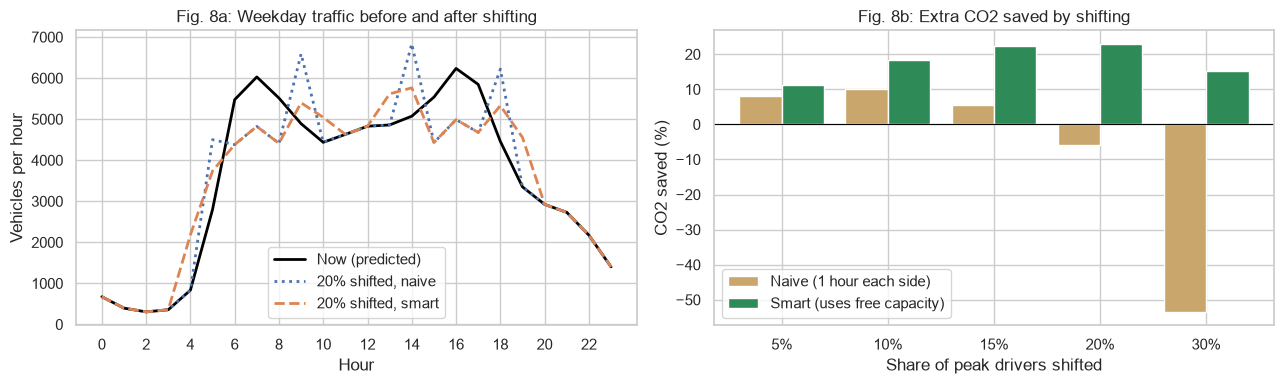

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(range(24), base.mean(axis=0), lw=2, color='black', label='Now (predicted)')
axes[0].plot(range(24), shift_peak(base, 0.20, smart=False).mean(axis=0), lw=2, ls=':', label='20% shifted, naive')
axes[0].plot(range(24), shift_peak(base, 0.20, smart=True).mean(axis=0), lw=2, ls='--', label='20% shifted, smart')
axes[0].set(title='Fig. 8a: Weekday traffic before and after shifting', xlabel='Hour', ylabel='Vehicles per hour')
axes[0].legend()
axes[0].set_xticks(range(0, 24, 2))

x = np.arange(len(SHARES))
axes[1].bar(x - 0.2, shift_table['CO2 saved % (naive)'], width=0.4, label='Naive (1 hour each side)', color='#c9a66b')
axes[1].bar(x + 0.2, shift_table['CO2 saved % (smart)'], width=0.4, label='Smart (uses free capacity)', color='seagreen')
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_xticks(x, shift_table.index)
axes[1].set(title='Fig. 8b: Extra CO2 saved by shifting', xlabel='Share of peak drivers shifted',
            ylabel='CO2 saved (%)')
axes[1].legend()
fig.tight_layout()
save(fig, 'fig8_peak_shift')
plt.show()

## 10. Riyadh

The UCI data is from the US, so we also collected our own data for Riyadh. Every 15 minutes our script (`riyadh_collector.py`) asks the TomTom Traffic Flow API for the current speed and the normal free-flow speed on 13 main roads, like King Fahd Road and the ring roads. TomTom does not give the number of cars, so here we work with speed and delay instead of traffic volume.

From each reading we calculate:

- congestion % = how much slower the road is than normal = 100 × (1 − current speed / free-flow speed)
- delay = current travel time − free-flow travel time

In Saudi Arabia the weekend is Friday and Saturday, so workdays here are Sunday to Thursday.

In [19]:
RIYADH_PATH = Path('data') / 'riyadh_traffic.csv'
ry = None
if RIYADH_PATH.exists():
    ry = pd.read_csv(RIYADH_PATH, parse_dates=['timestamp'],
                     dtype={'road': 'category', 'current_speed': 'float32', 'free_flow_speed': 'float32',
                            'current_travel_time': 'float32', 'free_flow_travel_time': 'float32'})
HAVE_RIYADH = ry is not None and len(ry) > 0

if HAVE_RIYADH:
    # TomTom sometimes marks a road as closed when only some lanes are closed (cars still move),
    # so we only drop readings where nothing is moving
    ry = ry[ry['current_speed'] > 0].copy()
    ry['congestion_pct'] = (100 * (1 - ry['current_speed'] / ry['free_flow_speed'])).clip(lower=0)
    ry['delay_min'] = ((ry['current_travel_time'] - ry['free_flow_travel_time']) / 60).clip(lower=0)

    # round to 15 minutes so all roads from the same run share one time
    ry['slot'] = ry['timestamp'].dt.round('15min')
    ry['hour'] = ry['slot'].dt.hour
    ry['dayofweek'] = ry['slot'].dt.dayofweek
    ry['is_weekend'] = ry['dayofweek'].isin([4, 5]).astype('int8')   # Friday and Saturday
    n_days = ry['slot'].dt.date.nunique()
    print(f'{len(ry):,} readings, {ry["road"].nunique()} roads, '
          f'{ry["slot"].min():%Y-%m-%d} to {ry["slot"].max():%Y-%m-%d} ({n_days} days)')
else:
    n_days = 0
    print('No Riyadh data yet. Run riyadh_collector.py or the GitHub Action first.')

No Riyadh data yet. Run riyadh_collector.py or the GitHub Action first.


In [20]:
if HAVE_RIYADH:
    workday = ry[ry['is_weekend'] == 0]
    heat = workday.pivot_table(index='road', columns='hour', values='congestion_pct', aggfunc='mean', observed=True)
    heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]

    fig, ax = plt.subplots(figsize=(12, 5))
    sns.heatmap(heat, cmap='rocket_r', ax=ax, cbar_kws={'label': 'Congestion (%)'})
    ax.set(title='Fig. 10: Congestion on Riyadh roads, Sunday to Thursday', xlabel='Hour', ylabel='')
    save(fig, 'fig10_riyadh_heatmap')
    plt.show()

    day_name = np.where(ry['is_weekend'] == 1, 'Weekend (Fri-Sat)', 'Workday (Sun-Thu)')
    by_hour = ry.groupby([day_name, 'hour'])['congestion_pct'].mean().unstack(0)
    fig, ax = plt.subplots(figsize=(9, 4))
    by_hour.plot(ax=ax, lw=2)
    ax.set(title='Fig. 11: Average congestion in Riyadh by hour', xlabel='Hour', ylabel='Congestion (%)')
    ax.set_xticks(range(0, 24, 2))
    save(fig, 'fig11_riyadh_hourly')
    plt.show()

    print('Worst road and hour on workdays (congestion %):')
    print(heat.stack().sort_values(ascending=False).head(5).round(1).to_string())

### 10.1 Predicting congestion in Riyadh

Same idea as section 6, but the levels come from how much slower than normal the road is:

| Level | Slower than free-flow by |
|---|---|
| Low | less than 15% |
| Moderate | 15 to 35% |
| High | 35 to 60% |
| Severe | more than 60% |

The features are the time, the day, the road, and the congestion 15 minutes, 1 hour and 1 day before. We train on the first 75% of the days and test on the rest. As a baseline we just assume the level stays the same as 15 minutes ago.

In [21]:
R_LEVELS = ['Low', 'Moderate', 'High', 'Severe']
R_CUTS = [15, 35, 60]
CAN_MODEL_RIYADH = HAVE_RIYADH and n_days >= 4

if CAN_MODEL_RIYADH:
    # one column per road on a full 15 minute grid, so shift(1) really means 15 minutes before
    wide = ry.pivot_table(index='slot', columns='road', values='congestion_pct', aggfunc='mean', observed=True)
    wide = wide.asfreq('15min')
    rmodel = pd.DataFrame({
        'congestion_pct': wide.stack(future_stack=True),
        'lag_1': wide.shift(1).stack(future_stack=True),
        'lag_4': wide.shift(4).stack(future_stack=True),
        'lag_96': wide.shift(96).stack(future_stack=True),
    }).reset_index().dropna()

    rmodel['hour'] = rmodel['slot'].dt.hour + rmodel['slot'].dt.minute / 60
    rmodel['hour_sin'] = np.sin(2 * np.pi * rmodel['hour'] / 24)
    rmodel['hour_cos'] = np.cos(2 * np.pi * rmodel['hour'] / 24)
    rmodel['dayofweek'] = rmodel['slot'].dt.dayofweek
    rmodel['is_weekend'] = rmodel['dayofweek'].isin([4, 5]).astype('int8')
    rmodel['road_code'] = rmodel['road'].astype('category').cat.codes
    rmodel['level'] = np.digitize(rmodel['congestion_pct'], R_CUTS)
    R_FEATURES = ['hour', 'hour_sin', 'hour_cos', 'dayofweek', 'is_weekend', 'road_code', 'lag_1', 'lag_4', 'lag_96']

    days = np.sort(rmodel['slot'].dt.normalize().unique())
    split_day = days[int(len(days) * 0.75)]
    r_train = rmodel[rmodel['slot'] < split_day]
    r_test = rmodel[rmodel['slot'] >= split_day]
    Xr_train, Xr_test = r_train[R_FEATURES].astype('float32'), r_test[R_FEATURES].astype('float32')
    yr_train, yr_test = r_train['level'], r_test['level']
    print(f'Train: {len(r_train):,} rows, test: {len(r_test):,} rows (test starts on {pd.Timestamp(split_day):%Y-%m-%d})')
    print('Test rows per level:', np.bincount(yr_test, minlength=4))

    r_models = {
        'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
        'Hist Gradient Boosting': HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=RANDOM_STATE),
    }
    r_rows, r_preds = [], {}
    baseline = np.digitize(r_test['lag_1'], R_CUTS)
    r_rows.append({'Model': 'Baseline (same as 15 min ago)', 'Accuracy': accuracy_score(yr_test, baseline),
                   'Macro F1': f1_score(yr_test, baseline, average='macro')})
    for name, model in r_models.items():
        model.fit(Xr_train, yr_train)
        pred = model.predict(Xr_test)
        r_preds[name] = pred
        r_rows.append({'Model': name, 'Accuracy': accuracy_score(yr_test, pred),
                       'Macro F1': f1_score(yr_test, pred, average='macro')})
    r_table = pd.DataFrame(r_rows).set_index('Model').sort_values('Accuracy', ascending=False)
    display(r_table)
elif HAVE_RIYADH:
    print(f'Only {n_days} day(s) of Riyadh data so far, we need at least 4 days to train the models.')

In [22]:
if CAN_MODEL_RIYADH:
    r_best = max(r_preds, key=lambda m: accuracy_score(yr_test, r_preds[m]))
    print('Best model for Riyadh:', r_best)
    print(classification_report(yr_test, r_preds[r_best], labels=[0, 1, 2, 3], target_names=R_LEVELS,
                                digits=3, zero_division=0))

    fig, ax = plt.subplots(figsize=(5, 4.2))
    cm = confusion_matrix(yr_test, r_preds[r_best], labels=[0, 1, 2, 3], normalize='true')
    ConfusionMatrixDisplay(np.nan_to_num(cm), display_labels=R_LEVELS).plot(ax=ax, cmap='Blues', values_format='.2f', colorbar=False)
    ax.set_title(f'Fig. 12: Riyadh confusion matrix ({r_best})')
    ax.grid(False)
    save(fig, 'fig12_riyadh_confusion')
    plt.show()

### 10.2 Extra CO2 for one driver in Riyadh

Without car counts we can't get the total CO2 on a road, but we can get it for one car using the same numbers as section 8: delay in hours × 0.4 gallons per hour × 8.887 kg per gallon. For each road we find the worst workday hour, and check how much one driver saves if they go one hour earlier or later instead. The delay is only for the part of the road TomTom measures, so a full trip would be more.

In [23]:
if HAVE_RIYADH:
    g_per_min = FUEL_GAL_PER_DELAY_H / 60 * CO2_KG_PER_GAL * 1000   # grams of CO2 per minute of delay
    road_hour = ry[ry['is_weekend'] == 0].groupby(['road', 'hour'], observed=True)['delay_min'].mean().unstack()

    rows = []
    for road, d in road_hour.iterrows():
        d = d.dropna()
        if d.empty:
            continue
        worst_h = int(d.idxmax())
        near = d.reindex([worst_h - 1, worst_h + 1]).dropna()
        moved = near.min() if len(near) else np.nan
        rows.append({'Road': road,
                     'Worst hour': f'{worst_h}:00',
                     'Delay at worst hour (min)': d.max(),
                     'Delay 1 hour away (min)': moved,
                     'CO2 per car at worst hour (g)': d.max() * g_per_min,
                     'CO2 saved per car (g)': (d.max() - moved) * g_per_min})
    co2_riyadh = pd.DataFrame(rows).set_index('Road').sort_values('Delay at worst hour (min)')

    fig, ax = plt.subplots(figsize=(9, 5))
    y = np.arange(len(co2_riyadh))
    ax.barh(y + 0.2, co2_riyadh['Delay at worst hour (min)'], height=0.4, label='At the worst hour', color='#c0504d')
    ax.barh(y - 0.2, co2_riyadh['Delay 1 hour away (min)'], height=0.4, label='1 hour earlier or later', color='seagreen')
    ax.set_yticks(y, co2_riyadh.index)
    ax.set(title='Fig. 13: Delay on Riyadh roads at the worst hour vs 1 hour away', xlabel='Delay (minutes)')
    ax.legend(loc='lower right')
    save(fig, 'fig13_riyadh_delay')
    plt.show()

    display(co2_riyadh.sort_values('CO2 per car at worst hour (g)', ascending=False).round(1))

## 11. Feature importance

We used permutation importance: each feature is shuffled in the test set and we check how much the MAE goes up. If the error goes up a lot, the model depends on that feature. We did it for the next hour model and for the planning model.

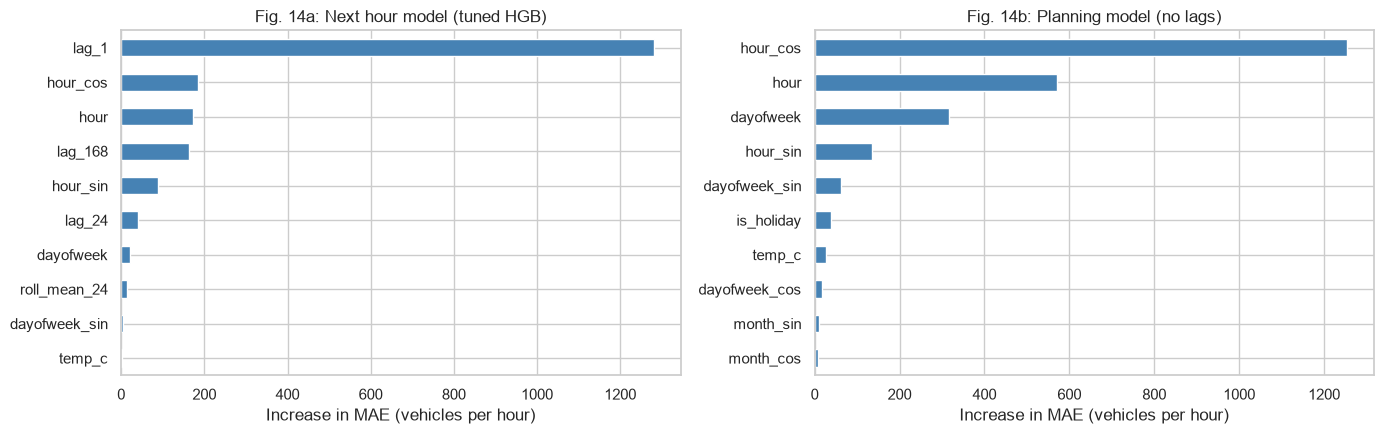

Importance of all weather features together (planning model): 27.3


In [24]:
def importance(model, X, y, title, ax):
    r = permutation_importance(model, X, y, n_repeats=5, random_state=RANDOM_STATE,
                               scoring='neg_mean_absolute_error', n_jobs=-1)
    imp = pd.Series(r.importances_mean, index=X.columns).sort_values().tail(10)
    imp.plot.barh(ax=ax, color='steelblue')
    ax.set(title=title, xlabel='Increase in MAE (vehicles per hour)')
    return imp


fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
imp_full = importance(best_reg, X_test, y_test, 'Fig. 14a: Next hour model (tuned HGB)', axes[0])
imp_plan = importance(plan_model, test[PLAN_FEATURES].astype('float32'), y_test, 'Fig. 14b: Planning model (no lags)', axes[1])
fig.tight_layout()
save(fig, 'fig14_importance')
plt.show()

weather_effect = imp_plan[imp_plan.index.isin(['temp_c', 'rain_1h', 'snow_1h', 'clouds_all'] + WEATHER_COLS)].sum()
print(f'Importance of all weather features together (planning model): {weather_effect:,.1f}')

## 12. Results summary

In [25]:
best_r = reg_table.iloc[0]
best_c = clf_table.iloc[0]
best_share = shift_table['CO2 saved % (smart)'].idxmax()

print(f'Memory saved: {100 * (1 - mem_after / mem_before):.1f}%')
print(f'Best regression model: {reg_table.index[0]} (R2 = {best_r.R2:.3f}, MAE = {best_r.MAE:,.0f})')
print(f'Planning model: R2 = {reg_table.loc["HGB planning model (no lags)", "R2"]:.3f}')
print(f'Best classifier: {clf_table.index[0]} (accuracy = {best_c.Accuracy:.1%}, macro F1 = {best_c["Macro F1"]:.3f})')
print(f'Number of day types (K-means): {best_k}')
print(f'Busiest 25% of hours make {100 * share_top:.0f}% of the extra CO2')
print(f'Best shift (smart): {best_share} of peak drivers, '
      f'{shift_table.loc[best_share, "CO2 saved % (smart)"]:.1f}% less extra CO2 '
      f'({shift_table.loc[best_share, "CO2 saved per year (t/mile, smart)"]:.1f} t per mile per year)')

if HAVE_RIYADH:
    print(f'Riyadh: {len(ry):,} readings over {n_days} days, average workday congestion {workday["congestion_pct"].mean():.1f}%')
    top = co2_riyadh['Delay at worst hour (min)'].idxmax()
    print(f'Riyadh worst road: {top} at {co2_riyadh.loc[top, "Worst hour"]}')
if CAN_MODEL_RIYADH:
    print(f'Riyadh best model: {r_table.index[0]} (accuracy = {r_table.iloc[0].Accuracy:.1%})')

Memory saved: 89.8%
Best regression model: Hist Gradient Boosting (R2 = 0.987, MAE = 145)
Planning model: R2 = 0.964
Best classifier: Hist Gradient Boosting (accuracy = 92.8%, macro F1 = 0.929)
Number of day types (K-means): 3
Busiest 25% of hours make 77% of the extra CO2
Best shift (smart): 20% of peak drivers, 22.9% less extra CO2 (9.8 t per mile per year)


### What we found

1. Traffic is easy to predict on this road. The next hour model got R2 = 0.987 on 2018 (MAE around 145 cars per hour), compared to an MAE of around 310 for linear regression. Even the planning model without lag features got R2 = 0.964.
2. The congestion level was predicted correctly 92.8% of the time. Most mistakes were between levels next to each other, like High and Severe.
3. K-means found 3 types of days: normal weekdays with two peaks, weekends with one wide peak in the middle of the day, and a small group of cold days, holidays and storm days with much less traffic (22% of them are holidays).
4. The busiest 25% of hours make about 77% of the extra CO2, because the delay grows very fast when the road gets close to its capacity.
5. The way drivers are moved matters a lot. With the naive way, moving more than 15% of drivers creates a new peak, and at 30% the CO2 goes up by 53%. With the smart way the extra CO2 goes down by up to 23% (about 9.8 tonnes per mile per year when 20% of drivers move).
6. Time is much more important than weather. The hour and the day of the week explain most of the traffic, and weather only has a small effect.
7. Riyadh: we will write this part after we finish collecting the data.

Limitations: the data is from one road in one direction in the US, the congestion levels are based on volume and not speed, and the CO2 numbers depend on our assumptions, so the percentages are more reliable than the tonnes.

## Appendix: memory optimization

| Section | What we did | Why |
|---|---|---|
| 1 | float32, int16 and int8 types | they use half the memory or less compared to 64-bit types |
| 1 | category type for text columns | each weather name is stored once |
| 1 | reading in chunks (chunksize=10,000) | only part of the file is processed at a time |
| 1 | del and gc.collect() | frees the temporary data |
| 3 | small types for all new features | keeps the table small after adding features |
| 5, 6 | float32 for the model inputs | half the memory of float64 |
| 5 | HistGradientBoosting | puts the values into bins, so it is faster and lighter than normal boosting |
| 5 to 7 | n_jobs=-1 | uses all CPU cores |
| 9 | numpy array for the simulation | faster and smaller than a DataFrame |

## Use of AI

We used AI (Claude) to guide us with the code and the formatting, and to fix the English in the report.